# **Redes Neuronales 2**
## Práctica 4: Redes neuronales recurrentes

**Temas:**
- Procesamiento de datos secuenciales.
- Entrenamiento de una RNN (retropropagación en el tiempo con autograd).
- Predicción a corto y largo plazo.
- Celdas con compuertas: LSTM y GRU.

Vamos a predecir cómo continúa una **señal senoidal** en el futuro, a partir de observaciones pasadas.

In [ ]:
# Imports y configuración básica
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, random_split

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

Usando dispositivo: cpu


### Construyendo la base de datos (provisto)

Creamos una base sintética de señales senoidales de frecuencia y fase aleatorias, y las partimos en tres tramos: **pasado** (entrada), **futuro inmediato** y **futuro remoto**.

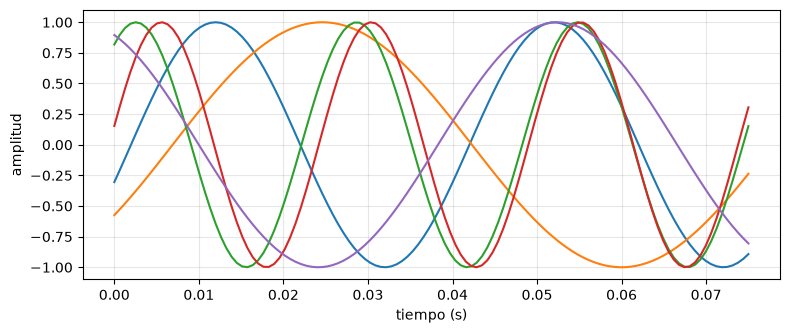

In [2]:
# Rango de frecuencias [f_min, f_max] (Hz), paso dt y duración T (s)
f_min, f_max = 10, 50
dt = 1.0 / (32.0 * f_max)      # resolvemos bien la señal más rápida
T = 0.75 / f_min               # cubrimos varios ciclos de la más lenta
n_steps = int(T / dt)
ts = np.linspace(0, T, n_steps)

n_total = 1000
signals = np.empty([n_total, n_steps])
for i in range(n_total):
    f = f_min + (f_max - f_min) * np.random.rand()
    fase = 2 * np.pi * np.random.rand()
    signals[i] = np.sin(fase + 2 * np.pi * f * ts)

fig, ax = plt.subplots(figsize=(9, 3.5))
for i in range(0, n_total, 200):
    ax.plot(ts, signals[i])
ax.set(xlabel="tiempo (s)", ylabel="amplitud"); ax.grid(alpha=0.3)
plt.show()

In [4]:
signals.shape #1000 señales de 120 (es un dataset de señales sinusoidales)

# Partimos cada señal en tres tramos iguales
seq_len = n_steps // 3
x = signals[:, :seq_len]           # pasado (entrada de la red)
y = signals[:, seq_len:2*seq_len]  # futuro inmediato
z = signals[:, 2*seq_len:3*seq_len]  # futuro remoto

In [5]:
class SignalDataset(Dataset):
    def __init__(self, X, Y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.Y = torch.tensor(Y, dtype=torch.float32)
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return self.X[i], self.Y[i]

# particiones train / val / test
n_val = n_test = int(0.2 * n_total) #0.2 del total de sñeales
n_train = n_total - n_val - n_test #0.6 del total de señales


idx = np.random.permutation(n_total) #mezclamos las señales? 
tr_idx, va_idx, te_idx = idx[:n_train], idx[n_train:n_train+n_val], idx[-n_test:]
batch_size = 32


train_loader = DataLoader(SignalDataset(x[tr_idx], y[tr_idx]), batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(SignalDataset(x[va_idx], y[va_idx]), batch_size=256)
test_loader  = DataLoader(SignalDataset(x[te_idx], y[te_idx]), batch_size=256)

print(f"train {n_train}, val {n_val}, test {n_test}, seq_len {seq_len}")

train 600, val 200, test 200, seq_len 40


### La red recurrente (provista)

La predicción se construye únicamente a partir del **estado final** de la parte recurrente: si funciona, toda la información relevante del pasado quedó comprimida en ese estado. El parámetro `celda` permite elegir entre `RNN`, `LSTM` y `GRU` (lo usaremos en el Ejercicio 2).

In [6]:
class ModeloRecurrente(nn.Module):
    def __init__(self, hidden_dim, seq_len_out, celda="RNN"):
        super().__init__()
        Celda = {
            "RNN": nn.RNN, 
            "LSTM": nn.LSTM, 
            "GRU": nn.GRU}[celda]
        self.rec = Celda(input_size=1, hidden_size=hidden_dim,
                         num_layers=1, batch_first=True)
        self.fc = nn.Linear(hidden_dim, seq_len_out)

    def forward(self, x):
        # x: (batch, seq_len) -> (batch, seq_len, 1)
        salida, _ = self.rec(x.unsqueeze(-1))
        h_final = salida[:, -1, :]        # estado final de la secuencia
        return self.fc(h_final)

criterion = nn.MSELoss()

def entrenar_con_early_stopping(modelo, train_loader, val_loader,
                                lr=1e-3, max_epochs=400, patience=15, verbose=True):
    modelo = modelo.to(device)
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    mejor_val, mejor_sd, j = np.inf, None, 0
    hist = {"train": [], "val": []}
    for ep in range(max_epochs):
        modelo.train()
        tot, n = 0.0, 0
        for X, Y in train_loader:
            X, Y = X.to(device), Y.to(device)
            opt.zero_grad()
            loss = criterion(modelo(X), Y)
            loss.backward()
            opt.step()
            tot += loss.item() * len(X); n += len(X)
        modelo.eval()
        with torch.no_grad():
            val = np.mean([criterion(modelo(X.to(device)), Y.to(device)).item()
                           for X, Y in val_loader])
        hist["train"].append(tot / n); hist["val"].append(val)
        if val < mejor_val:
            mejor_val, j = val, 0
            mejor_sd = {k: v.clone() for k, v in modelo.state_dict().items()}
        else:
            j += 1
            if j >= patience:
                break
        if verbose and ep % 25 == 0:
            print(f"época {ep}: train {tot/n:.4f} | val {val:.4f}")
    modelo.load_state_dict(mejor_sd)
    if verbose:
        print(f"mejor val: {mejor_val:.4f} (época {len(hist['val'])-j-1})")
    return hist

def perdida_en(modelo, loader):
    modelo.eval()
    with torch.no_grad():
        return np.mean([criterion(modelo(X.to(device)), Y.to(device)).item()
                        for X, Y in loader])

## Parte a) Futuro cercano (provisto)

Entrenamos la RNN para predecir el futuro inmediato `y` a partir del pasado `x`, con _early stopping_ sobre validación.

época 0: train 0.4748 | val 0.4331
época 25: train 0.1218 | val 0.1114
época 50: train 0.0284 | val 0.0632
época 75: train 0.0086 | val 0.0135
mejor val: 0.0129 (época 82)


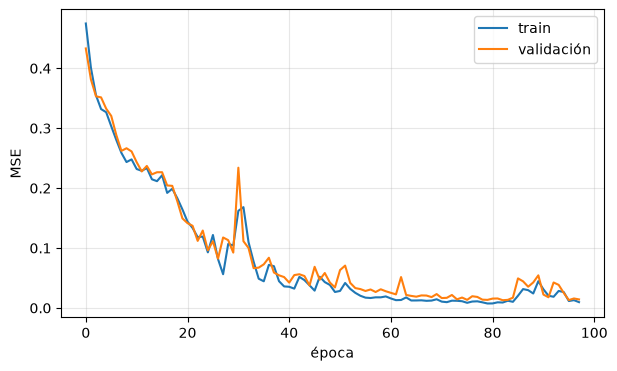

MSE en test (futuro cercano): 0.0080


In [7]:
torch.manual_seed(SEED)
modelo = ModeloRecurrente(hidden_dim=100, seq_len_out=seq_len, celda="RNN")
hist = entrenar_con_early_stopping(modelo, train_loader, val_loader)

plt.figure(figsize=(7, 4))
plt.plot(hist["train"], label="train"); plt.plot(hist["val"], label="validación")
plt.xlabel("época"); plt.ylabel("MSE"); plt.legend(); plt.grid(alpha=0.3); plt.show()

print(f"MSE en test (futuro cercano): {perdida_en(modelo, test_loader):.4f}")

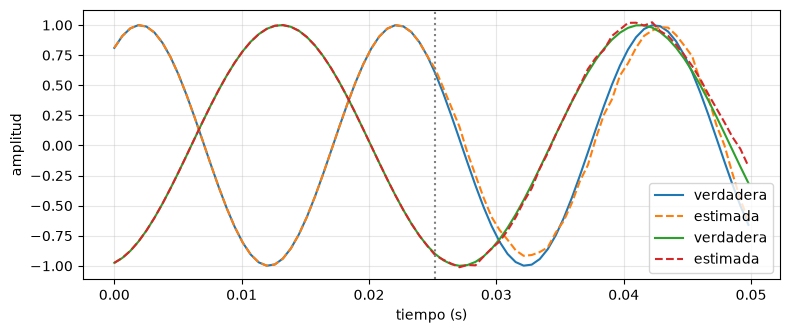

In [ ]:
# inspección visual sobre un ejemplo de test
def graficar_prediccion(modelo, i=3):
    modelo.eval()
    with torch.no_grad():
        y_pred = modelo(torch.tensor(x[te_idx], dtype=torch.float32).to(device)).numpy()
    ts_fc = ts[:2 * seq_len]
    fig, ax = plt.subplots(figsize=(9, 3.5))
    ax.plot(ts_fc, np.concatenate([x[te_idx][i], y[te_idx][i]]), label="verdadera")
    ax.plot(ts_fc, np.concatenate([x[te_idx][i], y_pred[i]]), "--", label="estimada")
    
    ax.axvline(ts[seq_len], color="gray", ls=":")
    ax.set(xlabel="tiempo (s)", ylabel="amplitud"); ax.legend(); ax.grid(alpha=0.3)
    plt.show()

graficar_prediccion(modelo)


---
## Ejercicio 1: futuro remoto

Usar el **mismo modelo, sin reentrenar**, para predecir el futuro remoto `z` a partir del pasado `x`. Evaluar el MSE sobre el conjunto de test y graficar un ejemplo (pasado + futuro cercano + futuro remoto).

*Nota: no vale usar los valores verdaderos del futuro próximo `y` ( ni del futuro remoto, obviamente). Puedo utilizar todo lo demás.

In [ ]:
#deberia entonces usar las predicciones del futuro cercano como futuro remoto

#primero calculo las salidas del modelo a los datos de X_test
with torch.no_grad():
    x_test = torch.tensor(x[te_idx], dtype = torch.float32).to(device)
    y_pred = modelo(x_test).cpu().numpy() #futuro cercano

    #entrada extendida
    entrada_extendida = np.concatenate([x[te_idx], y_pred], axis = 1) #concateno por columna
    nueva_ventana = entrada_extendida[:, -seq_len:] #solo para ver la parte nueva

    x_futuro = torch.tensor(nueva_ventana, dtype = torch.float32).to(device)
    y_futuro = modelo(x_futuro).cpu().numpy()


#graficacion


(200, 40)
(200, 40)


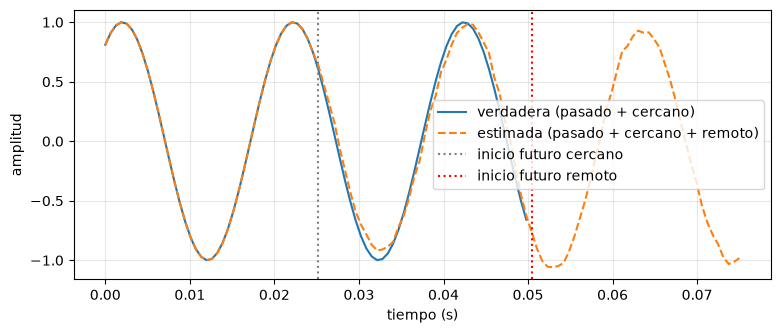

In [18]:
def graficar_prediccion_remoto(modelo, i=3):
    modelo.eval()
    seq_len = x.shape[1]
    seq_len_out = y.shape[1]

    with torch.no_grad():
        x_test = torch.tensor(x[te_idx], dtype=torch.float32).to(device)
        y_pred = modelo(x_test).cpu().numpy()  # futuro cercano

        # rollout: deslizo la ventana para predecir el futuro remoto
        entrada_extendida = np.concatenate([x[te_idx], y_pred], axis=1)
        nueva_ventana = entrada_extendida[:, -seq_len:]
        x_futuro = torch.tensor(nueva_ventana, dtype=torch.float32).to(device)
        y_futuro = modelo(x_futuro).cpu().numpy()  # futuro remoto

    # dominio temporal: pasado + futuro cercano + futuro remoto
    largo_total = seq_len + seq_len_out + y_futuro.shape[1]
    ts_fc = ts[:largo_total]

    fig, ax = plt.subplots(figsize=(9, 3.5))

    verdadera = np.concatenate([x[te_idx][i], y[te_idx][i]])
    estimada = np.concatenate([x[te_idx][i], y_pred[i], y_futuro[i]])

    ax.plot(ts[:seq_len + seq_len_out], verdadera, label="verdadera (pasado + cercano)")
    ax.plot(ts_fc, estimada, "--", label="estimada (pasado + cercano + remoto)")

    ax.axvline(ts[seq_len], color="gray", ls=":", label="inicio futuro cercano")
    ax.axvline(ts[seq_len + seq_len_out], color="red", ls=":", label="inicio futuro remoto")

    ax.set(xlabel="tiempo (s)", ylabel="amplitud")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.show()

graficar_prediccion_remoto(modelo)

---
## Ejercicio 2: RNN vs. LSTM vs. GRU

La clase `ModeloRecurrente` ya acepta `celda ∈ {"RNN", "LSTM", "GRU"}`.

- a) Entrenar los tres modelos con la misma configuración (hidden 100, misma semilla) y comparar las curvas de validación y el MSE de test en futuro cercano y remoto.
- b) ¿Cuántos parámetros tiene cada modelo? ¿Por qué LSTM tiene ~4× los de la RNN y GRU ~3×?

In [20]:
# ====================== COMPLETAR ======================
# ========================================================

models = ["RNN", "LSTM", "GRU"]
historial = {}
modelos = {}
for m in models:
    torch.manual_seed(SEED)
    modelo = ModeloRecurrente(hidden_dim=100, seq_len_out=seq_len, celda=m)
    hist = entrenar_con_early_stopping(modelo, train_loader, val_loader, lr=1e-3, max_epochs=400, patience=15, verbose=True)
    historial[m] = hist
    modelos[m] = modelo
    print(m, "params:", sum(p.numel() for p in modelo.parameters()))

época 0: train 0.4748 | val 0.4331
época 25: train 0.1218 | val 0.1114
época 50: train 0.0284 | val 0.0632
época 75: train 0.0086 | val 0.0135
mejor val: 0.0129 (época 82)
RNN params: 14340
época 0: train 0.4902 | val 0.4654
época 25: train 0.0175 | val 0.0262
época 50: train 0.0052 | val 0.0066
época 75: train 0.0028 | val 0.0030
época 100: train 0.0040 | val 0.0049
mejor val: 0.0020 (época 94)
LSTM params: 45240
época 0: train 0.4784 | val 0.4470
época 25: train 0.0346 | val 0.0320
época 50: train 0.0090 | val 0.0107
época 75: train 0.0040 | val 0.0045
época 100: train 0.0021 | val 0.0023
mejor val: 0.0017 (época 110)
GRU params: 34940


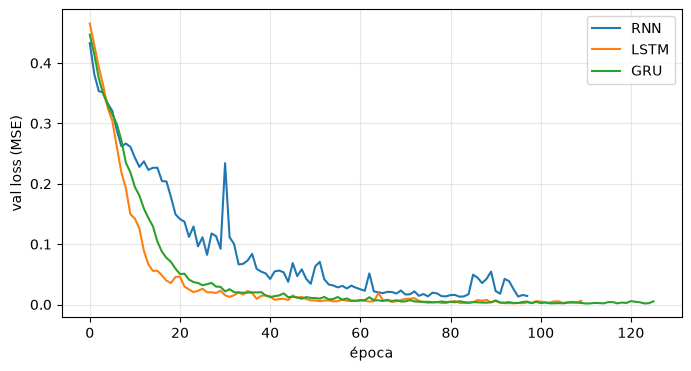

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
for m in models:
    ax.plot(historial[m]["val"], label=m)
ax.set(xlabel="época", ylabel="val loss (MSE)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [26]:
for n, modelo in modelos.items():
    #predicicon para futuro cercano
    MSE_cercano= perdida_en(modelo,test_loader)
    print(f"{n}: {MSE_cercano}")

RNN: 0.00803108885884285
LSTM: 0.003110120538622141
GRU: 0.001526681357063353


In [ ]:
#necestio ver el MSE en futuro lejano


---
## Ejercicio 3: para pensar

- a) En este problema la red solo ve el **estado final** de la parte recurrente. ¿Qué información tuvo que aprender a guardar ahí para poder predecir el futuro?
- b) ¿Qué pasaría si la señal tuviera una frecuencia fuera del rango de entrenamiento? Probarlo: generar señales con $f = 2 f_{max}$ y evaluar el modelo.

In [ ]:
# ====================== COMPLETAR ======================
# =======================================================